## Processing FireProtDB

In [68]:
import pandas as pd

fireprotdb_df = pd.read_csv('../../data/raw/fireprotdb.csv')
# Filter out empty DDG values
fireprotdb_df = fireprotdb_df.dropna(subset=['ddG'])
# Keep the essential columns
fireprotdb_df = fireprotdb_df[['position','mutation','sequence', 'ddG']]
# Rename the sequence column to wild_seq
fireprotdb_df = fireprotdb_df.rename(columns={'sequence': 'wild_seq', 'ddG': 'ddg'})

C:\Users\dante\AppData\Local\Temp\ipykernel_13960\1951883937.py:3: DtypeWarning: Columns (23,24,25,26,29) have mixed types. Specify dtype option on import or set low_memory=False.
  fireprotdb_df = pd.read_csv('../../data/raw/fireprotdb.csv')


In [70]:
def construct_mutant(sequence, position, mutation):
    """ 
    Constructs the mutant sequence using the
    original sequence, the mutant and its position.
    """
    try:
        sequence = list(sequence)
        sequence[position - 1] = mutation
        sequence = ''.join(sequence)
        return sequence
    
    except Exception as e: 
        print(f'error for {''.join(sequence)} {position} {mutation}', e)
        return None

In [71]:
fireprotdb_df['mutant_seq'] = fireprotdb_df.apply(lambda row: construct_mutant(row['wild_seq'], row['position'], row['mutation']), axis=1, result_type='expand')

In [72]:
fireprotdb_df = fireprotdb_df.drop(columns=['position', 'mutation'])

In [ ]:
fireprotdb_df[fireprotdb_df.isnull().any(axis=1)] # Check for null rows

,wild_seq,ddg,mutant_seq


## Processing Tsuboyama's Megascale Dataset

In [78]:
import pandas as pd

tsuboyama_df = pd.read_csv('../../data/raw/Tsuboyama2023_Dataset2_Dataset3_20230416.csv')

C:\Users\dante\AppData\Local\Temp\ipykernel_13960\1834416938.py:3: DtypeWarning: Columns (30,31,36) have mixed types. Specify dtype option on import or set low_memory=False.
  tsuboyama_df = pd.read_csv('../../data/raw/Tsuboyama2023_Dataset2_Dataset3_20230416.csv')


In [79]:
# Remove unreliable DDG samples and wild-type mutations
tsuboyama_df = tsuboyama_df[(tsuboyama_df['ddG_ML'] != '-') & (tsuboyama_df['mut_type'] != 'wt')]
# Rename aa_seq to mutant_seq
tsuboyama_df = tsuboyama_df.rename(columns={'aa_seq': 'mutant_seq', 'ddG_ML': 'ddg'})

In [80]:
def parse_megascale(mut_type):
    """
    Parses mutations for Tsuboyama's dataset.
    Assumes that there are no "wt" values.
    """
    if mut_type.startswith('ins'):
        # Handles insertion (example: insA13)
        wild_aa = ""
        location = int(mut_type[4:])
        mutant_aa = mut_type[3]
    elif mut_type.startswith('del'):
        # Handles deletion (example: delD1)
        wild_aa = mut_type[3]
        location = int(mut_type[4:])
        mutant_aa = ""
    else:
        # Handles substitution (example: A11B)
        wild_aa = mut_type[0]
        location = int(mut_type[1:-1])
        mutant_aa = mut_type[1:-1]

    return wild_aa, location, mutant_aa

def construct_wild(mutant_sequence, mutation_code):
    """
    Reconstructs the wild-type sequence from
    a mutant sequence and the mutation code.
    """
    try:
        sequence = list(mutant_sequence)
        for mutation in mutation_code.split(':'):
            wild_aa, location, mutant_aa = parse_megascale(mutation)
            index = location - 1 

            if mutant_aa == "":
                # Handle a deletion
                sequence[index:index] = wild_aa
            else:
                # Handle substitution or insertion
                sequence[location - 1] = wild_aa
                
        sequence = ''.join(sequence)
        return sequence
    except Exception as e: 
        print(f'error for {''.join(mutant_sequence)} {mutation_code}', e)
        return None

In [81]:
tsuboyama_df['wild_seq'] = tsuboyama_df.apply(lambda row: construct_wild(row['mutant_seq'], row['mut_type']), axis=1, result_type='expand')

In [82]:
tsuboyama_df = tsuboyama_df[['wild_seq', 'mutant_seq', 'ddg']]

In [83]:
tsuboyama_df

,wild_seq,mutant_seq,ddg
5,DEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,QEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,-0.07229644734890961
6,DEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,EEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,-0.0676614464832106
7,DEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,NEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,-0.04581499779145215
8,DEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,HEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,-0.08010508773722425
9,DEVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,REVTIHLGDKTIRVDGLDKELLEILKELARRGADEEELRKEIERWER,-0.40288893509481216
...,...,...,...
751664,ADDEVAKLLVDAYRKNDEDKLEEVKKRYNISDEQVKRLIRKVL,ADDEVAKLLVDAYRKNDEDKLEEVPKRYNISIEQVKRLIRKVL,-1.686936313496909
751665,ADDEVAKLLVDAYRKNDEDKLEEVKKRYNISDEQVKRLIRKVL,ADDEVAKLLVDAYRKNDEDKLEEVPKRYNISWEQVKRLIRKVL,-2.0475917540137454
751666,ADDEVAKLLVDAYRKNDEDKLEEVKKRYNISDEQVKRLIRKVL,ADDEVAKLLVDAYRKNDEDKLEEVPKRYNISYEQVKRLIRKVL,-2.125779191013127
751667,ADDEVAKLLVDAYRKNDEDKLEEVKKRYNISDEQVKRLIRKVL,ADDEVAKLLVDAYRKNDEDKLEEVPKRYNISFEQVKRLIRKVL,-2.081993302203348


In [84]:
tsuboyama_df[tsuboyama_df.isnull().any(axis=1)] # Check for null rows

,wild_seq,mutant_seq,ddg


## Processing ThermoMuteDB

In [85]:
import pandas as pd

thermomute_df = pd.read_json('../../data/raw/thermomutdb.json')

In [86]:
# Filter between 250K and 350K between pH 6 and pH 8
thermomute_df = thermomute_df[(thermomute_df['temperature'] > 250) & (thermomute_df['temperature'] < 350) & (thermomute_df['ph'] > 6) & (thermomute_df['ph'] < 8)]

# Remove where accesion ID is "-""
thermomute_df = thermomute_df[thermomute_df['uniprot'] != '-']

# The accession ID p01892 was changed to P04439
thermomute_df.loc[thermomute_df['uniprot'] == 'P01892', 'uniprot'] = 'P04439'

# Drop null ddg values
thermomute_df = thermomute_df.dropna(subset=['ddg'])  

In [87]:
import requests, json
from tqdm import tqdm 

base_url = 'https://rest.uniprot.org/uniprotkb/search?fields=sequence&query=accession_id:{accession_id}&format=json'

def get_sequence(accession_id):
    url = base_url.format(accession_id=accession_id)
    response = json.loads(requests.get(url).text)
    sequence = response['results'][0]['sequence']['value']
    return sequence

In [88]:
ids_sequences = {}

for accession_id in tqdm(set(thermomute_df['uniprot'])):
    try:
        sequence = get_sequence(accession_id)
        ids_sequences[accession_id] = sequence
    except Exception as e:
        print(f'Exception for {accession_id}:', e)

100%|██████████| 259/259 [01:53<00:00,  2.28it/s]


In [89]:
# Assign sequences to every row
thermomute_df['wild_seq'] = thermomute_df['uniprot'].apply(lambda accession_id: ids_sequences[accession_id])

In [93]:
def parse_mutation(mutation_code):
    """
    Parses a mutation's location, wild-type
    and mutant-type amino acids
    """
    location = int(''.join([char for char in mutation_code if char.isdigit()]))
    wild_aa = mutation_code.split(str(location))[0]
    mutant_aa = mutation_code.split(str(location))[-1]

    if len(mutant_aa) > 1:
        raise Exception('mutant_aa longer than 1 char:', mutant_aa)

    return wild_aa, location, mutant_aa

def generate_mutant(sequence, mutation_code):
    """
    Encodes the wild-type and the mutant
    residues within the protein sequence.
    """
    try:
        sequence = list(sequence)
        mutation_code = mutation_code.replace(';', ',').strip(',')

        for code in [code.strip() for code in mutation_code.split(',')]:
            # Apply each mutation code to the sequence
            wtaa, location, mtaa = parse_mutation(code)
            sequence[location - 1] = mtaa
            
        sequence = ''.join(sequence)
        return sequence
    
    except Exception as e: 
        print(f'error for {''.join(sequence)} {mutation_code}', e)
        return None

In [94]:
thermomute_df['mutant_seq'] = thermomute_df.apply(lambda row: generate_mutant(row['wild_seq'], row['mutation_code']), axis=1, result_type='expand')

error for MFENITAAPADPILGLADLFRADERPGKINLGIGVYKDETGKTPVLTSVKKAEQYLLENETTKNYLGIDGIPEFGRCTQELLFGKGSALINDKRARTAQTPGGTGALRVAADFLAKNTSVKRVWVSNPSWPNHKSVFNSAGLEVREYAYYDAENHTLDFDALINSLNEAQAGDVVLFHGCCHNPTGIDPTLEQWQTLAQLSVEKGWLPLFDFAYQGFARGLEEDAEGLRAFAAMHKELIVASSYSKNFGLYNERVGACTLVAADSETVDRAFSQMKAAIRANYSNPPAHGASVVATILSNDALRAIWEQELTDMRQRIQRMRQLFVNTLQEKGANRDFSFIIKQNGMFSFSGLTKEQVLRLREEFGVYAVASGRVNVAGMTPDNMAPLCEAIVAVL C401A list assignment index out of range
error for MFENITAAPADPILGLADLFRADERPGKINLGIGVYKDETGKTPVLTSVKKAEQYLLENETTKNYLGIDGIPEFGRCTQELAFGKGSALINDKRARTAQTPGGTGALRVAADFLAKNTSVKRVWVSNPSWPNHKSVFNSAGLEVREYAYYDAENHTLDFDALINSLNEAQAGDVVLFHGCCHNPTGIDPTAAQWQTLAQLSVEKGWLPLFDFAYQGFARGLEEDAEGLRAFAAMHKELIVASSYSKNFGLYNERVGACTLVAADSETVDAAFSQMKAAIRANYSNPPAHGASVVATILSNDALRAIWEQELTDMRQRIQRMRQLFVNTLQEKGANRDFSFIIKQNGMFSFSGLTKEQVLRLREEFGVYAVASGRVNVAGMTPDNMAPLCEAIVAVL C82A,C191A,C192A,C270A,C401A list assignment index out of range
error for MGVQVETISPGDGRTFPKRGQTCVVHYTGMLEDGKKFDSSRDRNKPFKFMLGKQEVIRGWEEGVAQMSVGQ

In [96]:
# Save the mutations, the encoded sequences and ddg
thermomute_df = thermomute_df[['wild_seq', 'mutant_seq', 'ddg']]

In [98]:
thermomute_df

,wild_seq,mutant_seq,ddg
0,MERYESLFAQLKERKEGAFVPFVTLGDPGIEQSLKIIDTLIEAGAD...,MERYESLFAQLKERKEGAFVPFVTLGDPGIEQSLKIIDTLIEAGAD...,4.60
1,MERYESLFAQLKERKEGAFVPFVTLGDPGIEQSLKIIDTLIEAGAD...,MERYESLFAQLKERKEGAFVPFVTLGDPGIEQSLKIIDTLIEAGAD...,-2.50
5,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,-3.07
6,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,-4.78
7,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLS...,-4.54
...,...,...,...
13318,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSVNSEIYQRVMESFK...,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSVNSEIYQAVMESFK...,-4.60
13319,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSVNSEIYQRVMESFK...,MKGMSKMPQFNLRWPREVLDLVRKAAEENGRSVNSEIYQRVMESFK...,-0.40
13320,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSVNSEIYQRVMESFK...,MKGMSKMPQFNLRWPREALDLVRKVAEENGRSVNSEIYQRVMESFK...,-0.50
13321,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSVNSEIYQRVMESFK...,MKGMSKMPQFNLRWPREVLDLVRKVAEENGRSANSEIYQRVMESFK...,-2.10


In [97]:
thermomute_df[thermomute_df.isnull().any(axis=1)]

,wild_seq,mutant_seq,ddg
654,MFENITAAPADPILGLADLFRADERPGKINLGIGVYKDETGKTPVL...,None,3.200000
655,MFENITAAPADPILGLADLFRADERPGKINLGIGVYKDETGKTPVL...,None,-1.000000
3807,MGVQVETISPGDGRTFPKRGQTCVVHYTGMLEDGKKFDSSRDRNKP...,None,-1.400000
3999,ASTKGPSVFPLAPSSKSTSGGTAALGCLVKDYFPEPVTVSWNSGAL...,None,-2.500000
4000,ASTKGPSVFPLAPSSKSTSGGTAALGCLVKDYFPEPVTVSWNSGAL...,None,-2.100000
4001,ASTKGPSVFPLAPSSKSTSGGTAALGCLVKDYFPEPVTVSWNSGAL...,None,-2.400000
6087,MQRGKVKWFNNEKGYGFIEVEGGSDVFVHFTAIQGEGFKTLEEGQE...,None,-1.552499
6102,MQRGKVKWFNNEKGYGFIEVEGGSDVFVHFTAIQGEGFKTLEEGQE...,None,0.023885
6107,MQRGKVKWFNNEKGYGFIEVEGGSDVFVHFTAIQGEGFKTLEEGQE...,None,-0.286615
6117,MQRGKVKWFNNEKGYGFIEVEGGSDVFVHFTAIQGEGFKTLEEGQE...,None,-1.504730


In [100]:
thermomute_df = thermomute_df.dropna() # Drop empty values

In [ ]:
spysmith_df = pd.concat([fireprotdb_df, tsuboyama_df, thermomute_df])
# Convert all the DDG values to float
spysmith_df['ddg'] = spysmith_df['ddg'].apply(lambda ddg: float(ddg))
# Keep all sequences that are less than or equal to 1022 amino acids
spysmith_df = spysmith_df[spysmith_df['wild_seq'].apply(lambda s: len(s) <= 1022)]

In [102]:
spysmith_df['wild_seq'].apply(lambda s: len(s)).max()

np.int64(957)

In [104]:
spysmith_df.to_csv('../../data/processed/spysmith.csv', index=False)

In [105]:
import pandas as pd

spysmith_df = pd.read_csv('../../data/processed/spysmith.csv')

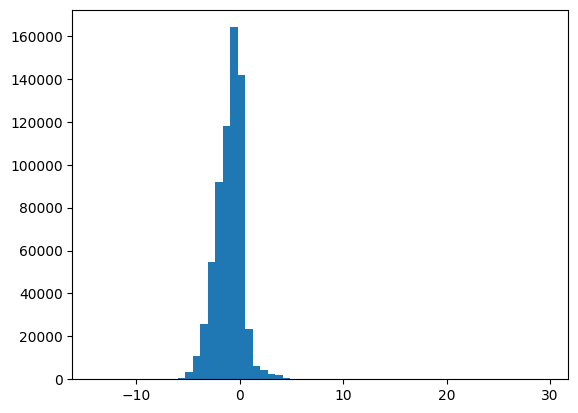

In [106]:
import matplotlib.pyplot as plt

plt.hist(spysmith_df['ddg'], bins=60)
plt.show()

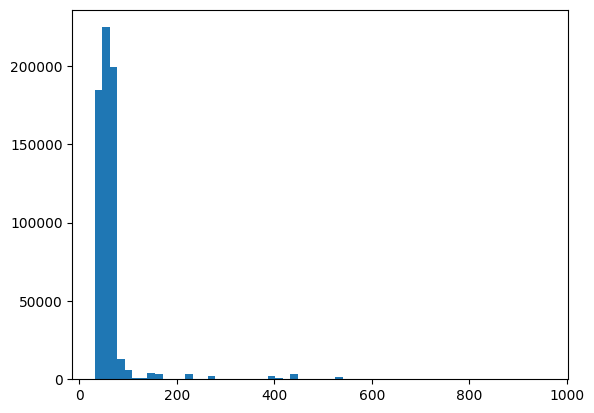

In [107]:
plt.hist(spysmith_df['wild_seq'].apply(lambda s: len(s)), bins=60)
plt.show()

In [67]:
from collections import Counter

print('min:', min(spysmith_df['ddg']))
print('max', max(spysmith_df['ddg']))
print('top 10 largest', sorted(spysmith_df['ddg'])[-10:])
print('top 10 smallest', sorted(spysmith_df['ddg'])[:10])
print('top 10: ', Counter(spysmith_df['ddg']).most_common(10))

min: -14.0
max 29.616904
top 10 largest [11.7, 11.9, 12.0, 12.2, 12.23, 12.4, 12.7, 13.7, 17.4, 29.616904]
top 10 smallest [-14.0, -13.7, -13.7, -13.7, -13.7, -13.7, -13.4, -12.7, -12.7, -12.7]
top 10:  [(0.2, 1625), (0.3, 1314), (0.7, 1053), (0.6, 1022), (0.8, 1018), (1.0, 981), (0.4, 906), (1.1, 848), (1.2, 794), (0.5, 772)]
